# CNN-Driven 3D Awareness Demo
### Multi-View Feature Matching → Point Cloud Reconstruction (Water Bottle Example)

This project demonstrates how **2D CNN feature representations** can be leveraged to approximate **3D object structure**,
using multiple images of the same object captured from different angles.

This is a simplified conceptual version of the core idea behind **NeRFs, 3D Gaussian Splatting, and generative 3D models**.

In [1]:
!pip install open3d==0.19.0 opencv-python-headless --quiet

import os, cv2, torch, zipfile
import numpy as np
import torchvision.models as models
import torchvision.transforms as T
from google.colab import files
from matplotlib import pyplot as plt
import open3d as o3d

print("✅ Environment Ready")


✅ Environment Ready


Saving bottle_images.zip to bottle_images (1).zip
✅ Loaded 12 images


(np.float64(-0.5), np.float64(959.5), np.float64(1279.5), np.float64(-0.5))

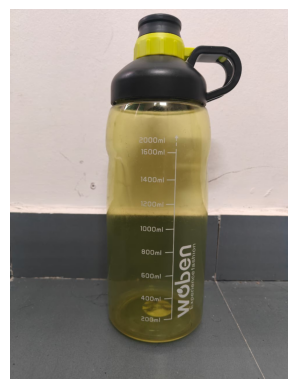

In [2]:
uploaded = files.upload()  # Upload your bottle_images.zip

zip_name = next(iter(uploaded))
extract_dir = "bottle_images"
os.makedirs(extract_dir, exist_ok=True)

with zipfile.ZipFile(zip_name, 'r') as zip_ref:
    zip_ref.extractall(extract_dir)

images = [cv2.imread(os.path.join(extract_dir, f))
          for f in sorted(os.listdir(extract_dir))
          if f.lower().endswith(('jpg','png','jpeg'))]

print(f"✅ Loaded {len(images)} images")
plt.imshow(cv2.cvtColor(images[0], cv2.COLOR_BGR2RGB))
plt.axis('off')


In [3]:
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
model = torch.nn.Sequential(*list(model.children())[:-2])  # remove FC layers
model.eval()

transform = T.Compose([T.ToPILImage(), T.Resize((224,224)), T.ToTensor()])

def extract_features(img):
    with torch.no_grad():
        x = transform(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)).unsqueeze(0)
        feats = model(x).squeeze().cpu().numpy()
    return feats

features = [extract_features(img) for img in images]
print("✅ Feature maps extracted:", features[0].shape)


✅ Feature maps extracted: (512, 7, 7)


In [4]:
orb = cv2.ORB_create()

keypoints, descriptors = [], []
for img in images:
    kp, des = orb.detectAndCompute(img, None)
    keypoints.append(kp)
    descriptors.append(des)

bf = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=True)
matches = bf.match(descriptors[0], descriptors[-1])
matches = sorted(matches, key=lambda x: x.distance)

print(f"✅ Matched {len(matches)} keypoints")


✅ Matched 135 keypoints


In [5]:
pts = []
for m in matches[:300]:
    (x1,y1) = keypoints[0][m.queryIdx].pt
    (x2,y2) = keypoints[-1][m.trainIdx].pt
    z = abs(x1 - x2)
    pts.append([x1, y1, z])

pts = np.array(pts)
pcd = o3d.geometry.PointCloud(o3d.utility.Vector3dVector(pts))
pcd.paint_uniform_color([0.2, 0.7, 1.0])
print("✅ Point Cloud Built")


✅ Point Cloud Built


In [6]:
!pip install plotly --quiet

import plotly.graph_objects as go

x = pts[:,0]
y = pts[:,1]
z = pts[:,2]

fig = go.Figure(data=[go.Scatter3d(
    x=x, y=y, z=z,
    mode='markers',
    marker=dict(size=3, color=z, colorscale='Viridis')
)])
fig.update_layout(
    title="3D Point Cloud Approximation (Interactive)",
    scene=dict(
        xaxis_title='X',
        yaxis_title='Y',
        zaxis_title='Z',
    ),
    width=700,
    height=700
)
fig.show()


In [ ]:
o3d.visualization.webrtc_server.enable_webrtc()
o3d.visualization.draw([pcd])